In [ ]:
# PRE PROCESSING DATA PROJECT 21 of December

In [ ]:
# "The software that can be used are Excel, SAS, PowerBI or any other you may want to use"

In [ ]:
!pip install feature-engine

In [ ]:
# Basic data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns  # prettier plots and pairplots

# Statistical summaries
from scipy.stats import zscore, pearsonr
import statsmodels.api as sm  # for VIF check (multicollinearity)

# Outlier treatment
from feature_engine.outliers import Winsorizer

# Clustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Evaluation
from sklearn.metrics import silhouette_score

# Export results
import os

In [ ]:
import pandas as pd

# nfile_path = "/content/sample_data/Project_Data.csv"

# Read the CSV
df = pd.read_csv(file_path)

# Quick look at structure
print(df.shape)      # (rows, columns)
print(df.columns)    # column names
df.head()

(10000, 21)
Index(['activity_id', 'timestamp', 'user_id', 'activity_type', 'duration_min',
       'distance_km', 'calories', 'avg_hr_bpm', 'max_hr_bpm', 'rpe', 'gender',
       'education_level', 'profession', 'marital_status', 'city',
       'device_model', 'age', 'height_cm', 'weight_kg', 'bmi', 'Random'],
      dtype='object')


,activity_id,timestamp,user_id,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm,rpe,...,education_level,profession,marital_status,city,device_model,age,height_cm,weight_kg,bmi,Random
0,14062,27/07/2025,1162,swim,61.8,NaN,609.5,135,152,10.1,...,Master's,Driver,Married,Newcastle,HealthBand Pro,30,160.6,61.8,24.0,0
1,13888,17/08/2025,1409,run,45.5,7.440,433.5,145,167,10.1,...,Bachelor's,Student,Single,Brighton,HealthBand X,18,181.2,53.9,16.4,0
2,10126,04/06/2025,1005,run,25.2,4.081,206.6,136,165,10.1,...,Bachelor's,Student,Single,Birmingham,FitPulse 3,18,176.6,NaN,24.9,0
3,10213,20/08/2025,1044,row,48.8,NaN,507.5,126,154,9.9,...,Master's,Accountant,Single,Bristol,FitPulse 4,22,178.4,76.3,24.0,1
4,15448,11/07/2025,1183,row,33.0,NaN,236.3,133,165,9.7,...,Master's,Marketing Specialist,Single,Southampton,HealthBand Pro,33,169.0,53.1,18.6,0


In [ ]:
# General information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   activity_id      10000 non-null  int64  
 1   timestamp        10000 non-null  object 
 2   user_id          10000 non-null  int64  
 3   activity_type    10000 non-null  object 
 4   duration_min     10000 non-null  float64
 5   distance_km      4465 non-null   float64
 6   calories         10000 non-null  float64
 7   avg_hr_bpm       10000 non-null  int64  
 8   max_hr_bpm       10000 non-null  int64  
 9   rpe              10000 non-null  float64
 10  gender           10000 non-null  object 
 11  education_level  10000 non-null  object 
 12  profession       9988 non-null   object 
 13  marital_status   10000 non-null  object 
 14  city             10000 non-null  object 
 15  device_model     10000 non-null  object 
 16  age              10000 non-null  int64  
 17  height_cm    

In [ ]:
# Basic descriptive statistics for numeric columns
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
activity_id,10000.0,14999.50,2886.90,10000.00,12499.75,14999.50,17499.25,19999.0
user_id,10000.0,1247.61,142.63,1001.00,1120.00,1254.00,1365.00,1500.0
duration_min,10000.0,41.50,12.28,20.00,32.70,40.80,49.50,240.3
distance_km,4465.0,6.58,3.69,1.32,3.46,5.90,9.15,42.0
calories,10000.0,332.70,155.66,45.00,210.55,318.05,431.60,1027.5
avg_hr_bpm,10000.0,125.14,9.04,94.00,119.00,125.00,131.00,158.0
max_hr_bpm,10000.0,150.24,10.88,110.00,143.00,150.00,158.00,230.0
rpe,10000.0,5.79,1.33,1.00,4.90,5.80,6.70,10.1
age,10000.0,34.77,10.93,18.00,26.00,34.00,42.00,70.0
height_cm,8995.0,169.51,9.26,148.80,161.50,169.10,177.10,196.7


In [ ]:
print("Education levels before standardization:")
df['education_level'].value_counts()

Education levels before standardization:


,count
education_level,
Master's,2888
Bachelor's,2819
A-levels,2787
Bachelor,1228
Doctorate,278


In [ ]:
df['education_level'] = df['education_level'].replace('Bachelor', 'Bachelor\'s')
print("Education levels after standardization:")
df['education_level'].value_counts()

Education levels after standardization:


,count
education_level,
Bachelor's,4047
Master's,2888
A-levels,2787
Doctorate,278


In [ ]:
# Check unique values for categorical columns
df.select_dtypes(include='object').nunique()

,0
timestamp,92
activity_type,9
gender,4
education_level,4
profession,20
marital_status,5
city,20
device_model,6


In [ ]:
df['rpe'].describe() # Checking rpe data interval

,rpe
count,10000.000000
mean,5.793830
std,1.334147
min,1.000000
25%,4.900000
50%,5.800000
75%,6.700000
max,10.100000


In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce') # Converting to data type time

/tmp/ipython-input-3010654244.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce') # Converting to data type time


In [ ]:
df['timestamp'].isna().sum() # How many dates were not converted

np.int64(0)

In [ ]:
# Basic descriptive statistics for numeric columns
df.describe().T

,count,mean,min,25%,50%,75%,max,std
activity_id,10000.0,14999.5,10000.0,12499.75,14999.5,17499.25,19999.0,2886.89568
timestamp,10000,2025-07-16 07:24:05.760000256,2025-06-01 00:00:00,2025-06-23 00:00:00,2025-07-16 00:00:00,2025-08-08 00:00:00,2025-08-31 00:00:00,NaN
user_id,10000.0,1247.6064,1001.0,1120.0,1254.0,1365.0,1500.0,142.625663
duration_min,10000.0,41.50308,20.0,32.7,40.8,49.5,240.3,12.277406
distance_km,4465.0,6.580249,1.315,3.465,5.904,9.152,42.0,3.690243
calories,10000.0,332.70106,45.0,210.55,318.05,431.6,1027.5,155.655446
avg_hr_bpm,10000.0,125.1383,94.0,119.0,125.0,131.0,158.0,9.03567
max_hr_bpm,10000.0,150.2377,110.0,143.0,150.0,158.0,230.0,10.877501
rpe,10000.0,5.79383,1.0,4.9,5.8,6.7,10.1,1.334147
age,10000.0,34.7713,18.0,26.0,34.0,42.0,70.0,10.929224


In [ ]:
# Check missing values
df.isnull().sum()

,0
activity_id,0
timestamp,0
user_id,0
activity_type,0
duration_min,0
distance_km,5535
calories,0
avg_hr_bpm,0
max_hr_bpm,0
rpe,0


In [ ]:
# List all unique activities
df['activity_type'].value_counts()

,count
activity_type,
run,1400
cycle,1251
swim,1161
strength_training,1148
hiit,1091
hike,1048
yoga,1042
row,948
walk,911


In [ ]:
# treating missing values
# distance is replaced by the mean of the activity
# profession will be NA
# weight and height will be filled by the mean of the gender and BMI
# However will treat outliers before attribuiting missing values to numerical variables

In [ ]:
df.groupby('activity_type')['distance_km'].mean().loc[['yoga', 'hiit', 'strength_training']]

,distance_km
activity_type,
yoga,NaN
hiit,NaN
strength_training,NaN


In [ ]:
df['profession'] = df['profession'].fillna('Unknown')
# for obv reasons. There is no mean of categorical categories nor can it be invented a profession

In [ ]:
# Check missing values
df.isnull().sum()

,0
activity_id,0
timestamp,0
user_id,0
activity_type,0
duration_min,0
distance_km,5535
calories,0
avg_hr_bpm,0
max_hr_bpm,0
rpe,0


In [ ]:
# Select key continuous variables for outlier inspection
numeric_cols = [
    'duration_min', 'distance_km', 'calories',
    'avg_hr_bpm', 'max_hr_bpm', 'rpe',
    'age', 'height_cm', 'weight_kg', 'bmi'
]

In [ ]:
# Display descriptive statistics to spot potential extreme min or max values
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
duration_min,10000.0,41.503080,12.277406,20.000,32.700,40.800,49.500,240.3
distance_km,4465.0,6.580249,3.690243,1.315,3.465,5.904,9.152,42.0
calories,10000.0,332.701060,155.655446,45.000,210.550,318.050,431.600,1027.5
avg_hr_bpm,10000.0,125.138300,9.035670,94.000,119.000,125.000,131.000,158.0
max_hr_bpm,10000.0,150.237700,10.877501,110.000,143.000,150.000,158.000,230.0
rpe,10000.0,5.793830,1.334147,1.000,4.900,5.800,6.700,10.1
age,10000.0,34.771300,10.929224,18.000,26.000,34.000,42.000,70.0
height_cm,8995.0,169.506581,9.261710,148.800,161.500,169.100,177.100,196.7
weight_kg,9481.0,63.847938,10.303947,45.000,54.700,63.700,72.100,97.3
bmi,10000.0,22.462760,3.269887,14.800,20.300,22.500,24.600,32.6


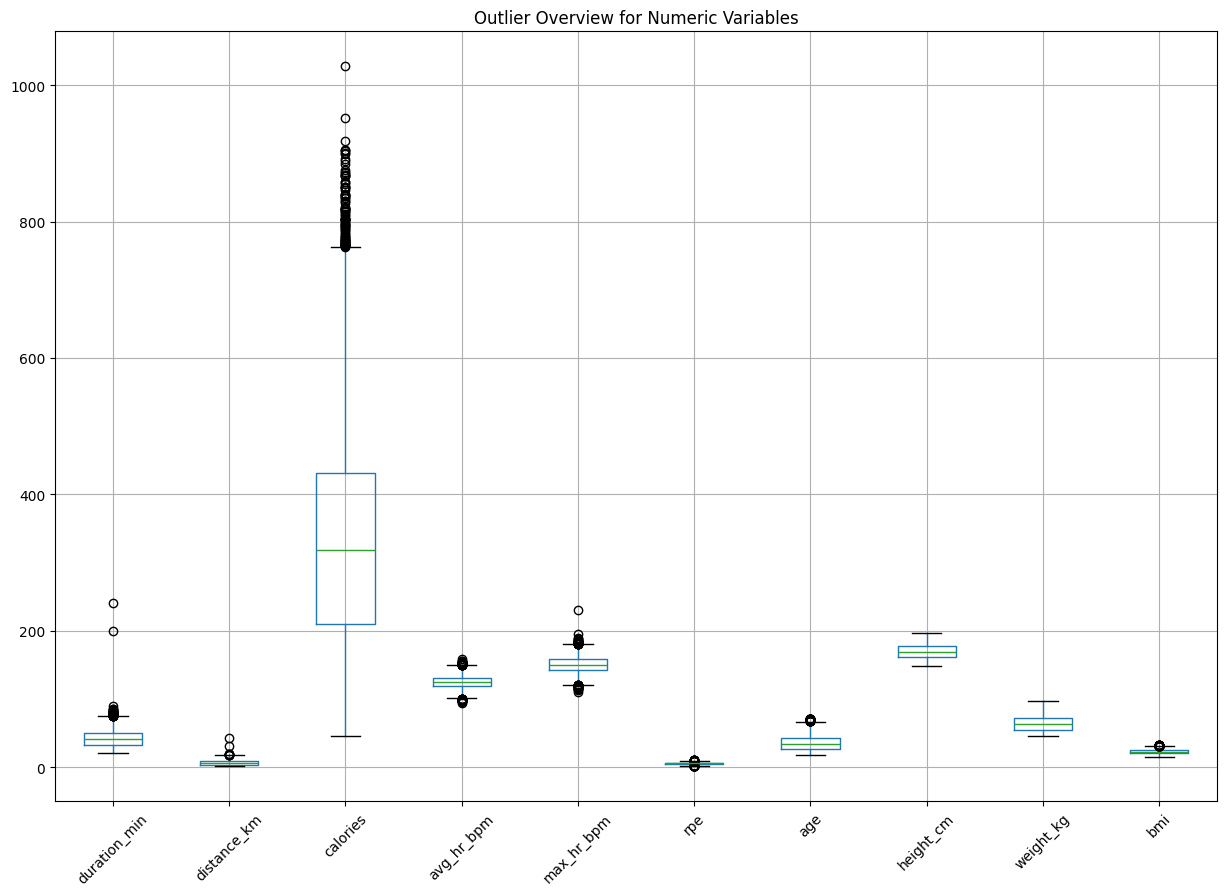

In [ ]:
# Quick overall boxplot to see which variables visually have outliers
import matplotlib.pyplot as plt

plt.figure(figsize=(15,10))
df[numeric_cols].boxplot()
plt.xticks(rotation=45)
plt.title("Outlier Overview for Numeric Variables")
plt.show()

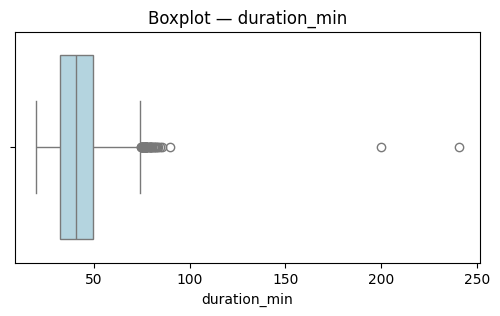

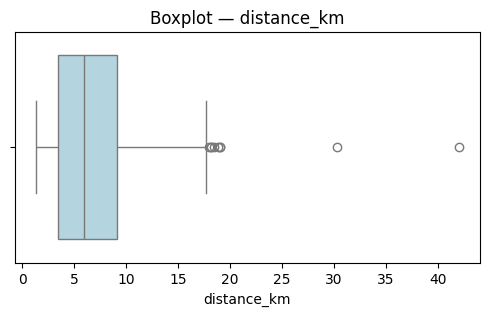

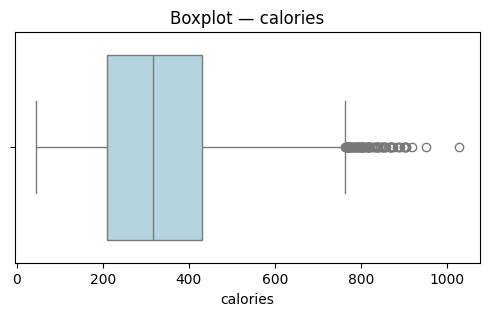

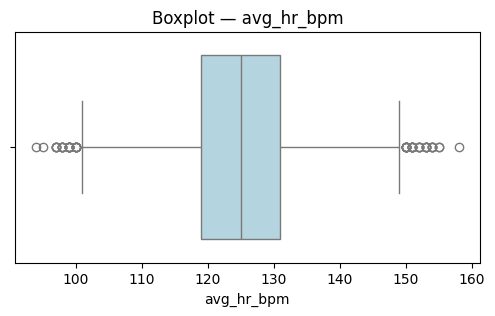

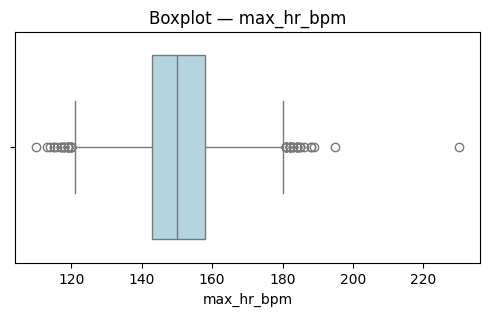

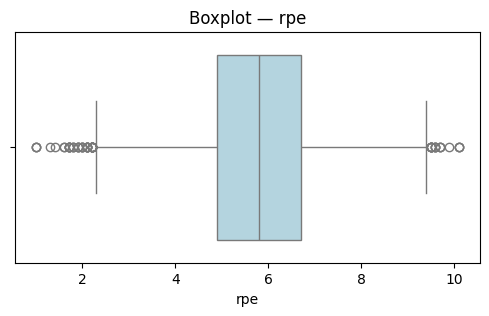

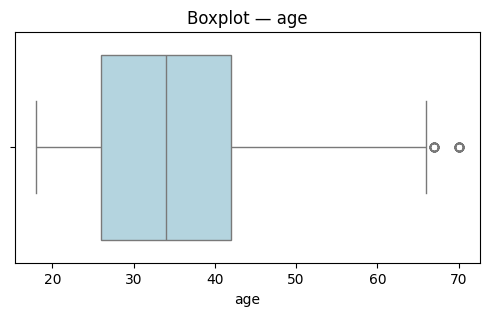

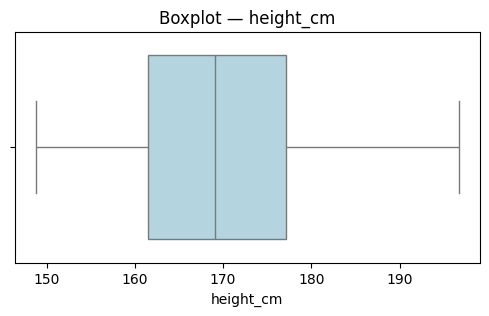

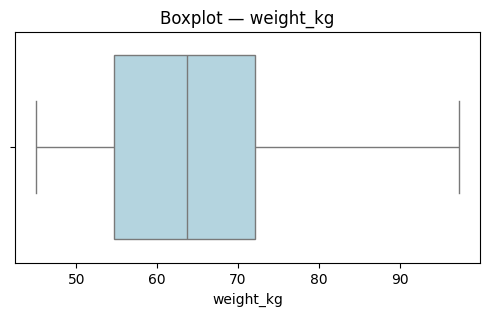

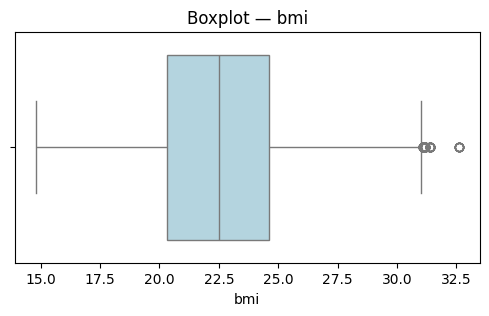

In [ ]:
# Separate boxplots per variable for detailed visual analysis
import seaborn as sns

for col in numeric_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col], color='lightblue')
    plt.title(f"Boxplot — {col}")
    plt.xlabel(col)
    plt.show()

In [ ]:
# BMI, weight, age and height - no need to touch
# rpe's max is 10.1 when the scale is interval from 0-10 so there is some outliers there and anything outside 1-10 should be trimmed
# Max BPM - Any heart rate at or above 200 bpm while exercising is considered dangerous for most adults. The 2 main outliers should be trimmed ( over 190)
# Average RPM - There are probably not any outliers here. All top average bpms are hiit and are farily near eachother, which make sense. Still will trimm the 158 as it is a little too deviated from top ones.
# Calories, distance and duration - Funnily enough, the highest numbers in calories are nowhere near the maximums for distance and duration, which means those are definitely outliers. Looking at the maximums for those it is clear as well that those are outliers. Calories is trickier as the numbers are definetely realistic for the time and activity. Still might trim up to 905
# distance - top 2 are definelely outliers and trim to 20
# duration trim to 91
# Conclusion : Anything out of 1-10 in RPE, over 190 in max bpm, 156 in average rpm, 905 in calories, 20 in distance and 91 in duration is an outlier and will be trimmed.

In [ ]:
df.nlargest(10, 'calories')[['activity_type', 'duration_min', 'distance_km', 'calories', 'avg_hr_bpm', 'max_hr_bpm']]

,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm
1003,run,70.2,11.573,1027.5,148,176
3032,swim,81.5,NaN,952.0,129,148
1378,run,74.0,11.998,918.4,144,163
3098,run,68.5,NaN,904.8,121,136
5390,cycle,70.0,16.832,904.6,122,142
1303,run,76.1,12.498,902.9,122,149
285,swim,77.4,NaN,900.0,130,149
141,swim,79.8,NaN,899.7,130,154
3937,run,67.6,10.956,891.1,134,157
196,swim,66.4,NaN,888.4,130,162


In [ ]:
df.nlargest(10, 'rpe')[['activity_type', 'duration_min', 'distance_km', 'calories', 'rpe', 'max_hr_bpm']]

,activity_type,duration_min,distance_km,calories,rpe,max_hr_bpm
0,swim,61.8,NaN,609.5,10.1,152
1,run,45.5,7.440,433.5,10.1,167
2,run,25.2,4.081,206.6,10.1,165
3,row,48.8,NaN,507.5,9.9,154
4,row,33.0,NaN,236.3,9.7,165
5,hiit,24.7,NaN,307.5,9.7,135
6,hiit,35.1,NaN,387.3,9.7,165
7,hiit,36.4,NaN,381.8,9.6,174
8,hiit,30.9,NaN,317.9,9.6,154
9,run,62.1,10.131,774.9,9.6,156


In [ ]:
# Count how many times each RPE value occurs
df['rpe'].value_counts().sort_index()

,count
rpe,
1.0,3
1.3,1
1.4,1
1.6,2
1.7,6
...,...
9.5,7
9.6,4
9.7,3


In [ ]:
df.nlargest(10, 'duration_min')[['activity_type', 'duration_min', 'distance_km', 'calories', 'avg_hr_bpm', 'max_hr_bpm']]

,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm
8215,yoga,240.3,NaN,80.0,119,150
9073,walk,200.0,42.000,97.9,113,134
9028,walk,90.0,30.307,56.9,120,142
4273,row,85.6,NaN,822.0,124,147
4407,hike,84.5,7.198,473.7,128,160
4467,run,83.7,13.428,640.7,139,161
5617,swim,83.3,NaN,608.5,138,157
140,run,82.7,13.280,624.6,124,145
1655,row,81.9,NaN,496.3,117,139
3032,swim,81.5,NaN,952.0,129,148


In [ ]:
df.nlargest(10, 'distance_km')[['activity_type', 'duration_min', 'distance_km', 'calories', 'avg_hr_bpm', 'max_hr_bpm']]

,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm
9073,walk,200.0,42.000,97.9,113,134
9028,walk,90.0,30.307,56.9,120,142
8564,cycle,79.8,19.057,626.7,129,149
6939,cycle,80.4,19.048,608.2,132,152
4005,cycle,79.1,18.863,711.4,125,143
2376,cycle,77.2,18.442,770.2,136,159
1441,cycle,74.7,18.144,696.1,147,163
4163,cycle,75.1,18.127,770.8,124,150
1642,cycle,75.4,17.948,540.8,129,148
3854,cycle,73.6,17.675,721.0,132,148


In [ ]:
df.nlargest(10, 'max_hr_bpm')[['activity_type', 'duration_min', 'distance_km', 'calories', 'avg_hr_bpm', 'max_hr_bpm']]

,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm
8028,walk,60.5,3.981,211.5,108,230
2397,run,51.8,8.475,710.9,146,195
2537,hiit,26.0,NaN,226.0,153,189
34,run,70.1,11.547,814.4,147,188
802,run,45.8,7.475,580.6,148,188
4314,hiit,55.1,NaN,762.7,155,186
217,hiit,44.9,NaN,479.4,148,185
6788,hike,45.2,3.893,378.3,144,185
7562,cycle,47.1,11.312,382.8,150,185
23,hiit,37.7,NaN,376.3,154,184


In [ ]:
df.nlargest(10, 'avg_hr_bpm')[['activity_type', 'duration_min', 'distance_km', 'calories', 'avg_hr_bpm', 'max_hr_bpm']]

,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm
3450,hiit,21.8,NaN,266.9,158,175
4314,hiit,55.1,NaN,762.7,155,186
6006,hiit,44.1,NaN,502.6,155,181
23,hiit,37.7,NaN,376.3,154,184
57,hiit,34.2,NaN,324.2,154,182
3380,hiit,25.0,NaN,313.7,154,179
5993,hiit,35.0,NaN,345.1,154,168
1137,hiit,47.0,NaN,477.5,153,181
2093,hiit,35.8,NaN,464.3,153,175
2537,hiit,26.0,NaN,226.0,153,189


In [ ]:
# Save original shape
original_shape = df.shape

filtered_df = df[
    (df['rpe'].between(1, 10, inclusive='both')) &
    (df['max_hr_bpm'].le(190) | df['max_hr_bpm'].isna()) &
    (df['avg_hr_bpm'].le(156) | df['avg_hr_bpm'].isna()) &
    (df['calories'].le(905) | df['calories'].isna()) &
    (df['distance_km'].le(20) | df['distance_km'].isna()) &
    (df['duration_min'].le(91) | df['duration_min'].isna())
]
print("Original:", df.shape)
print("After filtering:", filtered_df.shape)

Original: (10000, 21)
After filtering: (9988, 21)


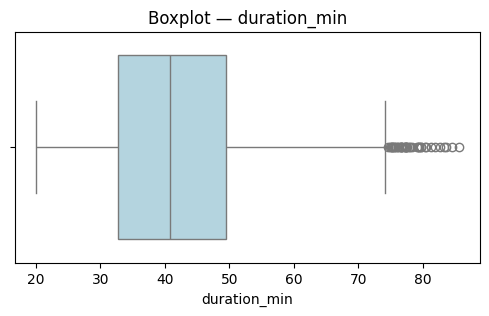

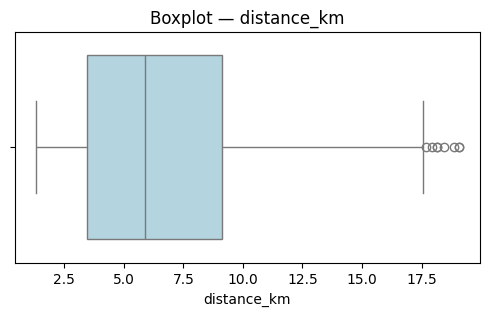

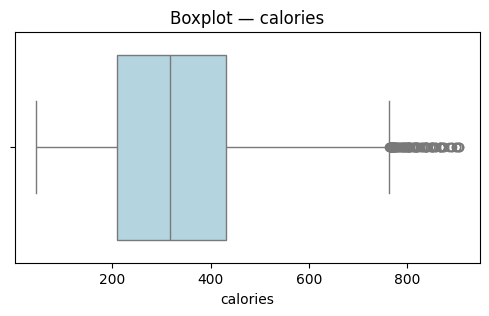

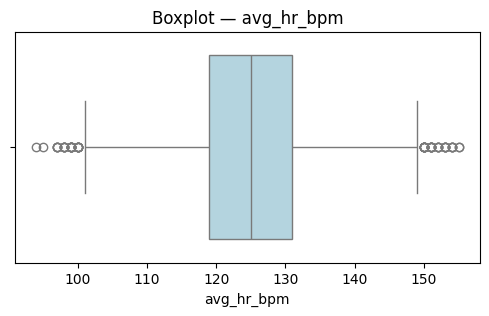

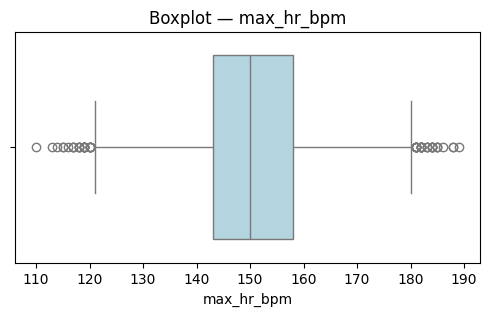

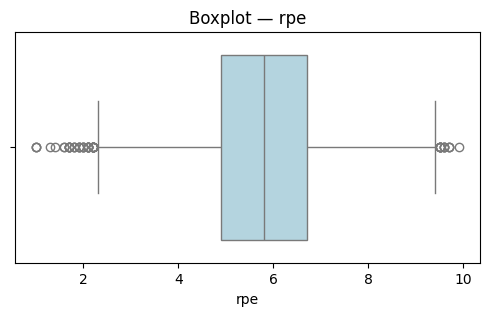

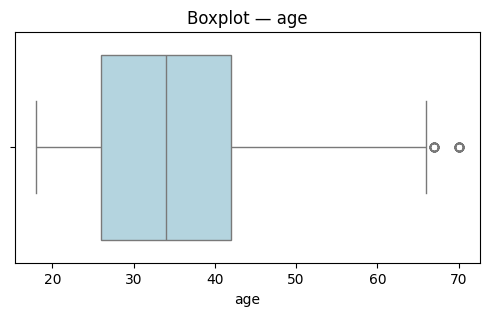

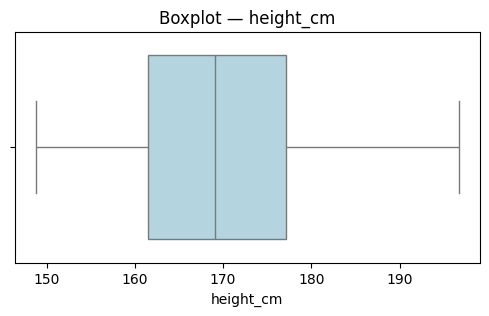

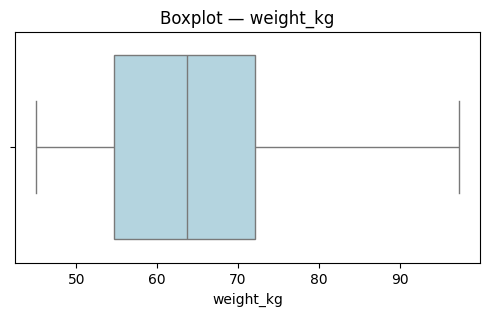

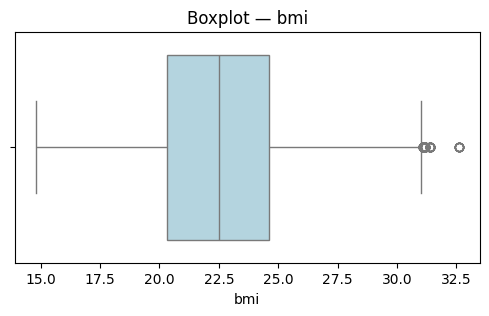

In [ ]:
# Separate boxplots per variable for detailed visual analysis (after filtering)
import seaborn as sns
import matplotlib.pyplot as plt

for col in numeric_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=filtered_df[col], color='lightblue')
    plt.title(f"Boxplot — {col}")
    plt.xlabel(col)
    plt.show()

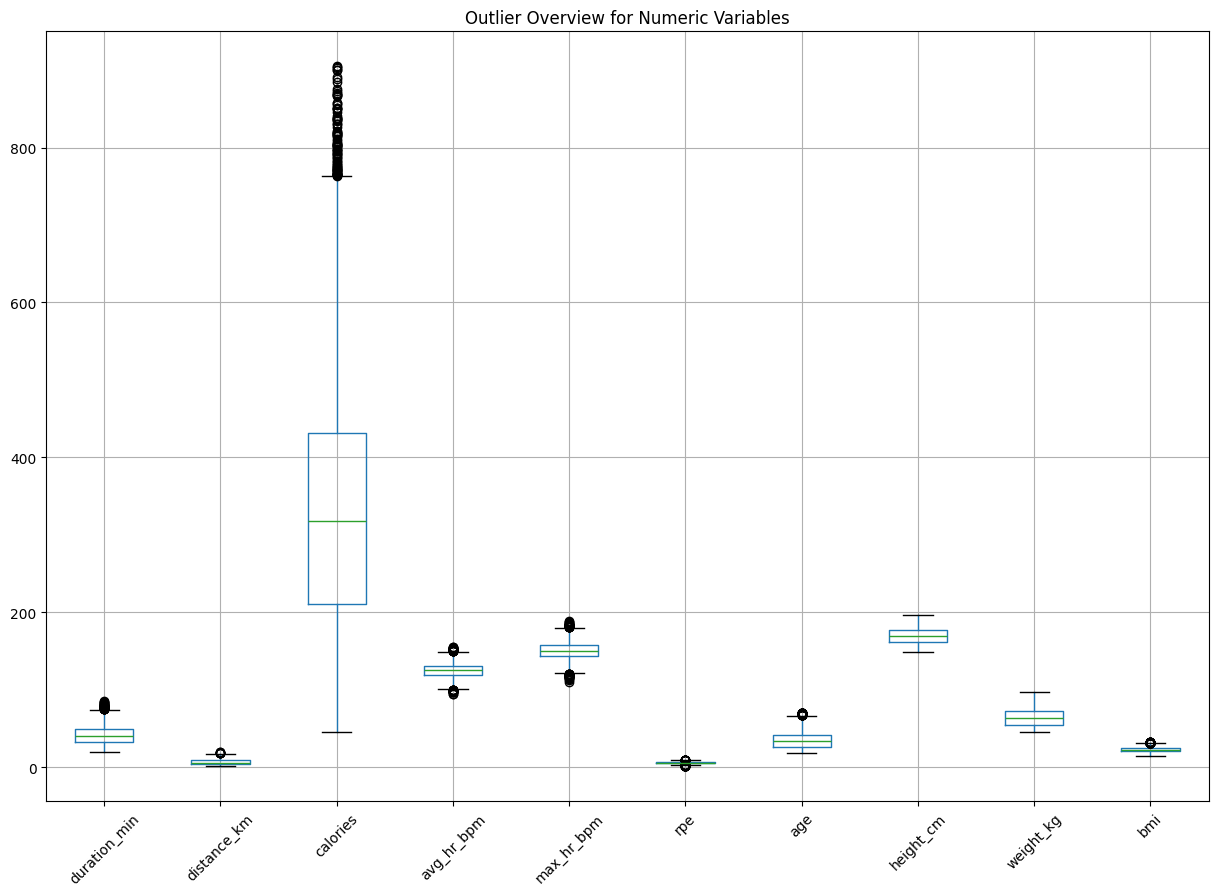

In [ ]:
# Quick overall boxplot to see which variables visually have outliers
import matplotlib.pyplot as plt

plt.figure(figsize=(15,10))
filtered_df[numeric_cols].boxplot()
plt.xticks(rotation=45)
plt.title("Outlier Overview for Numeric Variables")
plt.show()

In [ ]:
# Display descriptive statistics to spot potential extreme min or max values
filtered_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
duration_min,9988.0,41.450561,11.987557,20.000,32.700,40.800,49.500,85.600
distance_km,4457.0,6.565169,3.635679,1.315,3.461,5.899,9.142,19.057
calories,9988.0,332.542952,155.211395,45.000,210.675,318.050,431.525,904.800
avg_hr_bpm,9988.0,125.128354,9.021560,94.000,119.000,125.000,131.000,155.000
max_hr_bpm,9988.0,150.218262,10.834945,110.000,143.000,150.000,158.000,189.000
rpe,9988.0,5.792591,1.332256,1.000,4.900,5.800,6.700,9.900
age,9988.0,34.781538,10.925718,18.000,26.000,34.000,42.000,70.000
height_cm,8984.0,169.503595,9.260237,148.800,161.500,169.100,177.100,196.700
weight_kg,9471.0,63.845687,10.303395,45.000,54.700,63.700,72.100,97.300
bmi,9988.0,22.462165,3.269100,14.800,20.300,22.500,24.600,32.600


In [ ]:
# Cleaner now. Missing values now

In [ ]:
# Check missing values
filtered_df.isnull().sum()

,0
activity_id,0
timestamp,0
user_id,0
activity_type,0
duration_min,0
distance_km,5531
calories,0
avg_hr_bpm,0
max_hr_bpm,0
rpe,0


In [ ]:
# Count missing distance values per activity type
# Count total and missing distance values for each activity type
activity_missing_summary = (
    filtered_df
    .groupby('activity_type')['distance_km']
    .agg(
        total='size',
        missing=lambda x: x.isna().sum(),
        available=lambda x: x.notna().sum(),
        missing_pct=lambda x: (x.isna().sum() / len(x)) * 100
    )
    .reset_index()
    .sort_values(by='missing', ascending=False)
)

print(activity_missing_summary)

       activity_type  total  missing  available  missing_pct
6               swim   1159     1159          0   100.000000
5  strength_training   1148     1148          0   100.000000
1               hiit   1090     1090          0   100.000000
8               yoga   1041     1041          0   100.000000
3                row    948      948          0   100.000000
4                run   1395       41       1354     2.939068
7               walk    908       38        870     4.185022
0              cycle   1251       33       1218     2.637890
2               hike   1048       33       1015     3.148855


In [ ]:

filtered_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
duration_min,9988.0,41.450561,11.987557,20.000,32.700,40.800,49.500,85.600
distance_km,4457.0,6.565169,3.635679,1.315,3.461,5.899,9.142,19.057
calories,9988.0,332.542952,155.211395,45.000,210.675,318.050,431.525,904.800
avg_hr_bpm,9988.0,125.128354,9.021560,94.000,119.000,125.000,131.000,155.000
max_hr_bpm,9988.0,150.218262,10.834945,110.000,143.000,150.000,158.000,189.000
rpe,9988.0,5.792591,1.332256,1.000,4.900,5.800,6.700,9.900
age,9988.0,34.781538,10.925718,18.000,26.000,34.000,42.000,70.000
height_cm,8984.0,169.503595,9.260237,148.800,161.500,169.100,177.100,196.700
weight_kg,9471.0,63.845687,10.303395,45.000,54.700,63.700,72.100,97.300
bmi,9988.0,22.462165,3.269100,14.800,20.300,22.500,24.600,32.600


In [ ]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

df = filtered_df.copy()
df['distance_imputed'] = df['distance_km']

# Activities whose missing values should be set to 0
zero_activities = ['swim', 'strength_training', 'hiit', 'row', 'yoga']

# Activities to apply KNN
knn_activities = ['run', 'walk', 'cycle', 'hike']

features = ['duration_min', 'avg_hr_bpm', 'rpe', 'distance_km']

for activity in zero_activities:
    df.loc[(df['activity_type'] == activity) & (df['distance_km'].isna()), 'distance_imputed'] = 0

for activity in knn_activities:
    act_df = df[df['activity_type'] == activity].copy()
    if act_df['distance_km'].isna().sum() == 0:
        continue

    scaler = StandardScaler() # <-- data is standardized here
    scaled = scaler.fit_transform(act_df[features])

    imputer = KNNImputer(n_neighbors=10)   # KNN runs on standardized data
    imputed = imputer.fit_transform(scaled)
    imputed = scaler.inverse_transform(imputed)

    act_df['distance_imputed'] = imputed[:, -1] # <-- returned to original scale afterwards
    df.loc[act_df.index, 'distance_imputed'] = act_df['distance_imputed']

# Check result
print(df['distance_imputed'].isna().sum())

0


In [ ]:
df['distance_imputed'].isna().sum()

np.int64(0)

In [ ]:
print("distance_km missing:", df['distance_km'].isna().sum())
print("distance_imputed missing:", df['distance_imputed'].isna().sum())

distance_km missing: 5531
distance_imputed missing: 0


In [ ]:
(df.groupby('activity_type')['distance_imputed']
   .agg(['count', 'mean', 'min', 'max'])
   .sort_values(by='mean'))

,count,mean,min,max
activity_type,,,,
hiit,1090,0.000000,0.000,0.000
row,948,0.000000,0.000,0.000
swim,1159,0.000000,0.000,0.000
strength_training,1148,0.000000,0.000,0.000
yoga,1041,0.000000,0.000,0.000
walk,908,2.660055,1.315,5.037
hike,1048,3.869534,1.700,7.198
run,1395,7.372474,3.183,13.428
cycle,1251,10.718113,4.712,19.057


In [ ]:
(
    filtered_df
    .groupby('activity_type')['distance_km']
    .agg(['count', 'mean', 'min', 'max'])
    .sort_values(by='mean')
)

,count,mean,min,max
activity_type,,,,
walk,870,2.664297,1.315,5.037
hike,1015,3.873802,1.700,7.198
run,1354,7.366878,3.183,13.428
cycle,1218,10.703085,4.712,19.057
hiit,0,NaN,NaN,NaN
row,0,NaN,NaN,NaN
strength_training,0,NaN,NaN,NaN
swim,0,NaN,NaN,NaN
yoga,0,NaN,NaN,NaN


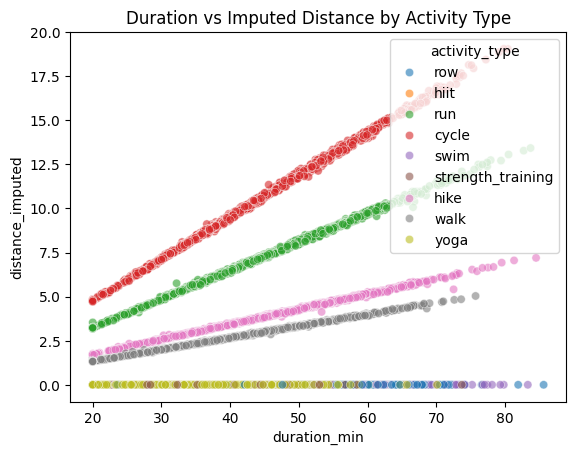

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x='duration_min',
    y='distance_imputed',
    hue='activity_type',
    alpha=0.6
)
plt.title('Duration vs Imputed Distance by Activity Type')
plt.show()

In [ ]:
valid = df[df['distance_km'].notna()]
print(valid[['distance_km', 'distance_imputed']].corr())
# . Optional — compare original vs imputed .  get a high correlation (~0.95+), confirming imputation didn’t distort valid values.

                  distance_km  distance_imputed
distance_km               1.0               1.0
distance_imputed          1.0               1.0


In [ ]:
# Replace the original column with the imputed one
df['distance_km'] = df['distance_imputed']

# Optionally remove the temporary column if you want to keep the dataset clean
df.drop(columns='distance_imputed', inplace=True)

In [ ]:
# Check missing values
df.isnull().sum()

,0
activity_id,0
timestamp,0
user_id,0
activity_type,0
duration_min,0
distance_km,0
calories,0
avg_hr_bpm,0
max_hr_bpm,0
rpe,0


In [ ]:
height_missing_summary = (
    filtered_df
    .groupby('activity_type')['height_cm']
    .agg(
        total='size',
        missing=lambda x: x.isna().sum(),
        available=lambda x: x.notna().sum(),
        missing_pct=lambda x: (x.isna().sum() / len(x)) * 100
    )
    .reset_index()
    .sort_values(by='missing', ascending=False)
)

print(height_missing_summary)

       activity_type  total  missing  available  missing_pct
4                run   1395      130       1265     9.318996
2               hike   1048      121        927    11.545802
6               swim   1159      117       1042    10.094909
0              cycle   1251      112       1139     8.952838
5  strength_training   1148      112       1036     9.756098
8               yoga   1041      110        931    10.566763
1               hiit   1090      109        981    10.000000
3                row    948      104        844    10.970464
7               walk    908       89        819     9.801762


In [ ]:
weight_missing_summary = (
    filtered_df
    .groupby('activity_type')['weight_kg']
    .agg(
        total='size',
        missing=lambda x: x.isna().sum(),
        available=lambda x: x.notna().sum(),
        missing_pct=lambda x: (x.isna().sum() / len(x)) * 100
    )
    .reset_index()
    .sort_values(by='missing', ascending=False)
)

print(weight_missing_summary)

       activity_type  total  missing  available  missing_pct
4                run   1395       72       1323     5.161290
0              cycle   1251       69       1182     5.515588
8               yoga   1041       63        978     6.051873
6               swim   1159       62       1097     5.349439
5  strength_training   1148       57       1091     4.965157
3                row    948       55        893     5.801688
1               hiit   1090       53       1037     4.862385
2               hike   1048       47       1001     4.484733
7               walk    908       39        869     4.295154


In [ ]:
# Count rows missing both height and weight
both_missing = filtered_df[
    filtered_df['height_cm'].isna() & filtered_df['weight_kg'].isna()
]

print(f"Rows missing both height and weight: {len(both_missing)}")

# Percentage of total
pct_missing_both = len(both_missing) / len(filtered_df) * 100
print(f"Percentage of rows missing both: {pct_missing_both:.2f}%")

Rows missing both height and weight: 0
Percentage of rows missing both: 0.00%


In [ ]:
df = df.copy()

# Fill missing height using BMI and weight
df.loc[df['height_cm'].isna(), 'height_cm'] = (
    np.sqrt(df.loc[df['height_cm'].isna(), 'weight_kg'] / df.loc[df['height_cm'].isna(), 'bmi']) * 100
)

# Fill missing weight using BMI and height
df.loc[df['weight_kg'].isna(), 'weight_kg'] = (
    df.loc[df['weight_kg'].isna(), 'bmi'] * ((df.loc[df['weight_kg'].isna(), 'height_cm'] / 100) ** 2)
)

In [ ]:
print("Missing height:", df['height_cm'].isna().sum())
print("Missing weight:", df['weight_kg'].isna().sum())

Missing height: 0
Missing weight: 0


In [ ]:
# Height comparison
height_comp = (
    filtered_df.groupby('activity_type')['height_cm']
    .agg(['count', 'mean', 'min', 'max'])
    .rename(columns={'mean': 'mean_before', 'min': 'min_before', 'max': 'max_before'})
    .merge(
        df.groupby('activity_type')['height_cm']
        .agg(['mean', 'min', 'max'])
        .rename(columns={'mean': 'mean_after', 'min': 'min_after', 'max': 'max_after'}),
        left_index=True, right_index=True
    )
)

# Weight comparison
weight_comp = (
    filtered_df.groupby('activity_type')['weight_kg']
    .agg(['count', 'mean', 'min', 'max'])
    .rename(columns={'mean': 'mean_before', 'min': 'min_before', 'max': 'max_before'})
    .merge(
        df.groupby('activity_type')['weight_kg']
        .agg(['mean', 'min', 'max'])
        .rename(columns={'mean': 'mean_after', 'min': 'min_after', 'max': 'max_after'}),
        left_index=True, right_index=True
    )
)

print("\nHeight comparison:")
print(height_comp.sort_values(by='mean_after'))
print("\nWeight comparison:")
print(weight_comp.sort_values(by='mean_after'))


Height comparison:
                   count  mean_before  min_before  max_before  mean_after  \
activity_type                                                               
walk                 819   169.296215       149.3       196.7  168.368517   
strength_training   1036   169.327799       148.8       196.7  168.398275   
hiit                 981   169.334149       148.8       196.7  168.410558   
run                 1265   169.354071       148.8       196.7  168.478414   
row                  844   169.547393       148.8       196.7  168.494802   
swim                1042   169.479559       148.8       196.7  168.528676   
hike                 927   169.795361       148.8       196.7  168.637261   
yoga                 931   169.741139       148.8       196.7  168.675081   
cycle               1139   169.682529       148.8       196.7  168.788513   

                   min_after  max_after  
activity_type                            
walk                   149.3      196.7  
streng

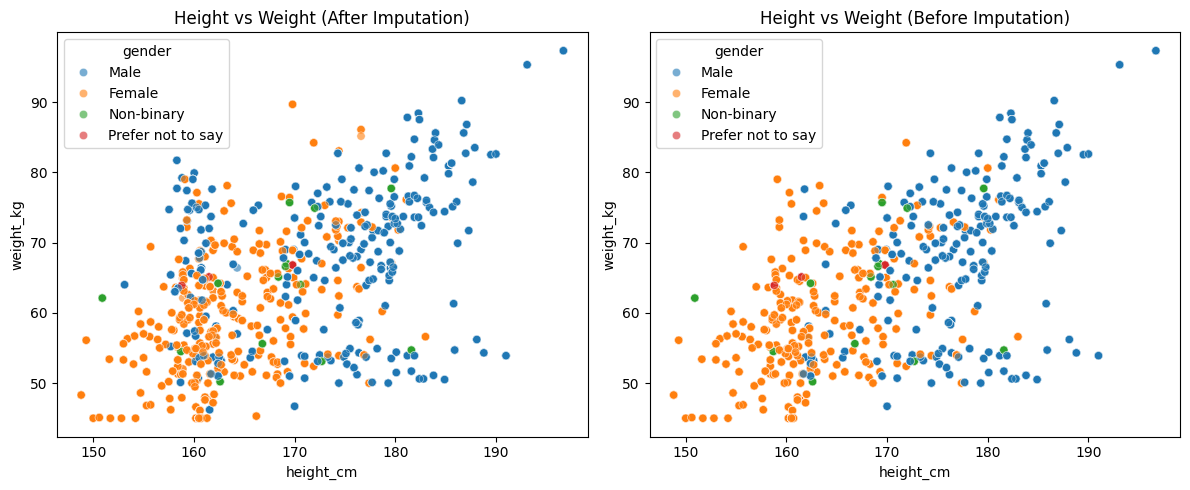

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=df, x='height_cm', y='weight_kg', hue='gender', alpha=0.6, ax=axes[0]
)
axes[0].set_title('Height vs Weight (After Imputation)')

sns.scatterplot(
    data=filtered_df, x='height_cm', y='weight_kg', hue='gender', alpha=0.6, ax=axes[1]
)
axes[1].set_title('Height vs Weight (Before Imputation)')

plt.tight_layout()
plt.show()

In [ ]:
valid_height = filtered_df[filtered_df['height_cm'].notna()]
valid_weight = filtered_df[filtered_df['weight_kg'].notna()]

print("Height correlation (orig vs imputed):",
      valid_height['height_cm'].corr(df.loc[valid_height.index, 'height_cm']).round(4))
print("Weight correlation (orig vs imputed):",
      valid_weight['weight_kg'].corr(df.loc[valid_weight.index, 'weight_kg']).round(4))

Height correlation (orig vs imputed): 1.0
Weight correlation (orig vs imputed): 1.0


In [ ]:
# Check missing values
df.isnull().sum()

,0
activity_id,0
timestamp,0
user_id,0
activity_type,0
duration_min,0
distance_km,0
calories,0
avg_hr_bpm,0
max_hr_bpm,0
rpe,0


In [ ]:
# Final analysis on the changes in the statistical variables to check if something signifcantly changed that could indicate the missing values were improperly attribuited

In [ ]:
df.query('height_cm < 140 or height_cm > 210 or weight_kg < 40 or weight_kg > 150')
#Check for unrealistic anthropometric outliers post‑formula — optional but worth one last scan:

,activity_id,timestamp,user_id,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm,rpe,...,education_level,profession,marital_status,city,device_model,age,height_cm,weight_kg,bmi,Random


In [ ]:
# Check skewness values for all numeric variables
numeric_df = df.select_dtypes(include=['float64', 'int64'])
skew_vals = numeric_df.skew().sort_values(ascending=False)
print(skew_vals)

distance_km     1.230649
calories        0.588056
age             0.439393
height_cm       0.350685
weight_kg       0.323988
duration_min    0.281649
bmi             0.127585
max_hr_bpm      0.017566
user_id         0.016033
activity_id    -0.000369
Random         -0.000401
avg_hr_bpm     -0.016589
rpe            -0.127435
dtype: float64


In [ ]:
df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
duration_min,9988.0,41.45,11.99,20.0,32.70,40.80,49.50,85.60
distance_km,9988.0,3.02,4.10,0.0,0.00,0.00,5.29,19.06
calories,9988.0,332.54,155.21,45.0,210.68,318.05,431.52,904.80
avg_hr_bpm,9988.0,125.13,9.02,94.0,119.00,125.00,131.00,155.00
max_hr_bpm,9988.0,150.22,10.83,110.0,143.00,150.00,158.00,189.00
rpe,9988.0,5.79,1.33,1.0,4.90,5.80,6.70,9.90
age,9988.0,34.78,10.93,18.0,26.00,34.00,42.00,70.00
height_cm,9988.0,168.54,9.26,148.8,160.60,167.30,176.30,196.70
weight_kg,9988.0,63.67,10.35,45.0,54.50,63.50,72.00,97.30
bmi,9988.0,22.46,3.27,14.8,20.30,22.50,24.60,32.60


In [ ]:
# Summary Statistics current

In [ ]:
# Coherence Checking

In [ ]:
fields_to_check = ['age', 'gender', 'height_cm', 'weight_kg', 'bmi', 'education_level', 'profession', 'marital_status', 'city', 'device_model']
all_incoherent_rows_list = []

for field in fields_to_check:
    # Find users who have more than one unique value for the current field
    inconsistent_users = df.groupby('user_id')[field].nunique()
    inconsistent_users = inconsistent_users[inconsistent_users > 1].index.tolist()

    if inconsistent_users:
        # Get all rows for these inconsistent users for the current field
        incoherent_data_for_field = df[df['user_id'].isin(inconsistent_users)].copy()
        incoherent_data_for_field['inconsistency_reason'] = f'Inconsistent {field}'
        all_incoherent_rows_list.append(incoherent_data_for_field)

# Combine all identified incoherent rows and remove duplicates based on activity_id
if all_incoherent_rows_list:
    all_incoherent_rows = pd.concat(all_incoherent_rows_list).drop_duplicates(subset=['activity_id'])
    print("--- All Incoherent Rows (User-Level Demographic Inconsistency) ---")
    display(all_incoherent_rows)
    print(f"\nTotal unique incoherent rows found: {len(all_incoherent_rows)}")
else:
    print("No incoherent rows found for user-level demographic consistency.")

--- All Incoherent Rows (User-Level Demographic Inconsistency) ---


,activity_id,timestamp,user_id,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm,rpe,...,profession,marital_status,city,device_model,age,height_cm,weight_kg,bmi,Random,inconsistency_reason
414,17975,2025-06-04,1019,cycle,33.0,8.0988,301.1,122,145,8.0,...,Chef,Married,Coventry,CardioTrack S,48,160.737599,66.4,25.7,0,Inconsistent height_cm
773,17001,2025-06-04,1010,row,49.7,0.0000,466.4,131,154,7.6,...,Electrician,Single,London,CardioTrack E,29,163.299316,64.0,24.0,0,Inconsistent height_cm
1185,13286,2025-07-13,1019,hiit,35.0,0.0000,410.1,137,157,7.3,...,Chef,Married,Coventry,CardioTrack S,48,179.535539,66.4,20.6,1,Inconsistent height_cm
1186,14028,2025-08-31,1019,run,44.3,7.0940,430.0,116,136,7.3,...,Chef,Married,Coventry,CardioTrack S,48,160.737599,66.4,25.7,1,Inconsistent height_cm
1336,16263,2025-07-30,1019,cycle,53.0,12.5810,459.3,105,141,7.2,...,Chef,Married,Coventry,CardioTrack S,48,160.737599,66.4,25.7,1,Inconsistent height_cm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9844,17391,2025-06-26,1289,walk,47.6,3.1420,238.2,111,127,2.8,...,Sales Representative,Single,Leicester,FitPulse 4,35,166.800000,55.6,23.8,0,Inconsistent bmi
9845,13260,2025-07-04,1022,yoga,35.1,0.0000,123.4,117,138,2.8,...,Researcher,Single,Southampton,HealthBand Pro,31,179.700000,73.7,22.8,0,Inconsistent bmi
9878,19642,2025-08-18,1011,yoga,43.6,0.0000,160.4,109,128,2.7,...,Police Officer,Married,Reading,HealthBand X,48,177.900000,80.0,24.9,0,Inconsistent bmi
9918,14621,2025-06-26,1102,yoga,44.1,0.0000,145.4,110,136,2.5,...,Software Engineer,Married,Leeds,CardioTrack E,52,169.100000,66.6,23.3,1,Inconsistent bmi



Total unique incoherent rows found: 535


In [ ]:
# Find a user_id that has inconsistent 'bmi' values
inconsistent_bmi_users = df.groupby('user_id')['bmi'].nunique()
inconsistent_bmi_users = inconsistent_bmi_users[inconsistent_bmi_users > 1].index.tolist()

if inconsistent_bmi_users:
    example_user_id_for_bmi = inconsistent_bmi_users[0] # Pick the first user found
    print(f"Example of a user (ID: {example_user_id_for_bmi}) with inconsistent 'bmi' values:")
    display(df[df['user_id'] == example_user_id_for_bmi][['activity_id', 'user_id', 'bmi', 'height_cm', 'weight_kg']].sort_values(by='activity_id'))
    print(f"\nAs you can see, for user {example_user_id_for_bmi}, the 'bmi' value changes across different activity records. This is what's flagged as an inconsistency.")
else:
    print("No users found with inconsistent 'bmi' values.")

Example of a user (ID: 1001) with inconsistent 'bmi' values:


,activity_id,user_id,bmi,height_cm,weight_kg
6611,10084,1001,21.2,161.9,55.568613
199,10355,1001,26.7,161.9,69.984999
4106,10657,1001,21.9,161.9,57.403426
7613,10696,1001,21.9,161.9,57.403426
1330,10707,1001,21.9,161.9,57.403426
3798,11081,1001,23.7,161.9,62.121516
1184,11623,1001,23.7,161.9,62.121516
8998,11757,1001,21.2,161.9,55.568613
9555,11846,1001,21.9,161.9,57.403426
3522,12686,1001,21.9,161.9,57.403426



As you can see, for user 1001, the 'bmi' value changes across different activity records. This is what's flagged as an inconsistency.


In [ ]:
inconsistency_summary = []

for incoherent_df_for_field in all_incoherent_rows_list:
    if not incoherent_df_for_field.empty:
        reason = incoherent_df_for_field['inconsistency_reason'].iloc[0]
        unique_users = incoherent_df_for_field['user_id'].nunique()
        total_activity_ids = incoherent_df_for_field['activity_id'].nunique()
        inconsistency_summary.append({
            'Inconsistency Reason': reason,
            'Unique Users Affected': unique_users,
            'Total Activity Records Affected': total_activity_ids
        })

if inconsistency_summary:
    summary_df = pd.DataFrame(inconsistency_summary)
    display(summary_df.sort_values(by='Total Activity Records Affected', ascending=False))
else:
    print("No inconsistencies found to summarize.")

,Inconsistency Reason,Unique Users Affected,Total Activity Records Affected
2,Inconsistent bmi,27,535
1,Inconsistent weight_kg,9,166
0,Inconsistent height_cm,2,25


In [ ]:
# Categories flagged as possible incoherences due to multiple unique numbers are bmi, height and weight

In [ ]:
# BMI and weight flutuate with time, as seen in 1001 where bmi moved the same as weight, so is fine. Height does not change most likely

In [ ]:
height_incoherent_rows = None
for incoherent_df in all_incoherent_rows_list:
    if 'Inconsistent height_cm' in incoherent_df['inconsistency_reason'].iloc[0]:
        height_incoherent_rows = incoherent_df
        break

if height_incoherent_rows is not None:
    display(height_incoherent_rows[['activity_id', 'user_id', 'height_cm', 'age', 'inconsistency_reason']].sort_values(by=['user_id', 'activity_id']))
    print(f"\nTotal activity records with inconsistent height_cm: {len(height_incoherent_rows)}")
else:
    print("No incoherent rows found for height_cm.")

,activity_id,user_id,height_cm,age,inconsistency_reason
5806,13615,1010,163.299316,29,Inconsistent height_cm
4654,13805,1010,163.299316,29,Inconsistent height_cm
9000,14783,1010,153.111800,29,Inconsistent height_cm
3249,15071,1010,153.111800,29,Inconsistent height_cm
8218,16142,1010,153.111800,29,Inconsistent height_cm
773,17001,1010,163.299316,29,Inconsistent height_cm
7164,17623,1010,153.111800,29,Inconsistent height_cm
3525,17713,1010,163.299316,29,Inconsistent height_cm
2177,17923,1010,153.111800,29,Inconsistent height_cm
4110,18386,1010,163.299316,29,Inconsistent height_cm



Total activity records with inconsistent height_cm: 25


In [ ]:
# Get the activity_ids of the incoherent height rows
incoherent_height_activity_ids = height_incoherent_rows['activity_id'].tolist()

# Drop these rows from the main DataFrame
df = df[~df['activity_id'].isin(incoherent_height_activity_ids)].copy()

print(f"Dropped {len(incoherent_height_activity_ids)} rows due to inconsistent heights.")
print(f"New DataFrame shape: {df.shape}")

Dropped 25 rows due to inconsistent heights.
New DataFrame shape: (9963, 21)


“For users presenting extreme inconsistencies in fixed biometric variables (e.g., height differing by more than a few centimeters across activity records), the true value cannot be recovered. These users are removed entirely from the dataset, as their biometric‑dependent metrics (BMI, energy estimation, intensity metrics) cannot be trusted for downstream clustering.”

In [ ]:
# for bmi vs weight they should be calculated together and are only incoherent if there are 2 bmis for weight and vice versa

In [ ]:
# there is a possibility the bmi wieght connection is incoherent as 110kg is 20 bmi (obv wrong) but those will be checked later here only unique values


In [ ]:
users_with_inconsistent_bmi_for_weight = set()
users_with_inconsistent_weight_for_bmi = set()

for user_id in df['user_id'].unique():
    user_data = df[df['user_id'] == user_id][['user_id', 'weight_kg', 'bmi']]

    # Check 1: If a given weight_kg is associated with more than one bmi value
    inconsistent_bmi_check = user_data.groupby('weight_kg')['bmi'].nunique()
    if (inconsistent_bmi_check > 1).any():
        users_with_inconsistent_bmi_for_weight.add(user_id)

    # Check 2: If a given bmi is associated with more than one weight_kg value
    inconsistent_weight_check = user_data.groupby('bmi')['weight_kg'].nunique()
    if (inconsistent_weight_check > 1).any():
        users_with_inconsistent_weight_for_bmi.add(user_id)

inconsistent_users_bmi_weight = list(users_with_inconsistent_bmi_for_weight.union(users_with_inconsistent_weight_for_bmi))

print(f"Number of users with inconsistent BMI for a given weight: {len(users_with_inconsistent_bmi_for_weight)}")
print(f"Number of users with inconsistent weight for a given BMI: {len(users_with_inconsistent_weight_for_bmi)}")
print(f"Total unique users with combined BMI-Weight inconsistencies: {len(inconsistent_users_bmi_weight)}")

Number of users with inconsistent BMI for a given weight: 16
Number of users with inconsistent weight for a given BMI: 0
Total unique users with combined BMI-Weight inconsistencies: 16


In [ ]:
inconsistent_bmi_weight_records = df[df['user_id'].isin(inconsistent_users_bmi_weight)].copy()

activity_ids_multiple_bmi_for_weight = set()
activity_ids_multiple_weight_for_bmi = set()

for user_id in inconsistent_users_bmi_weight:
    user_data = df[df['user_id'] == user_id][['activity_id', 'weight_kg', 'bmi']].copy()

    # Check for a given weight_kg associated with more than one bmi value
    for weight in user_data['weight_kg'].unique():
        b_values = user_data[user_data['weight_kg'] == weight]['bmi'].unique()
        if len(b_values) > 1:
            activity_ids_multiple_bmi_for_weight.update(user_data[user_data['weight_kg'] == weight]['activity_id'].tolist())

    # Check for a given bmi associated with more than one weight_kg value
    for bmi_val in user_data['bmi'].unique():
        w_values = user_data[user_data['bmi'] == bmi_val]['weight_kg'].unique()
        if len(w_values) > 1:
            activity_ids_multiple_weight_for_bmi.update(user_data[user_data['bmi'] == bmi_val]['activity_id'].tolist())

# Combine all identified inconsistent activity IDs for the final display, ensuring uniqueness
all_inconsistent_activity_ids = activity_ids_multiple_bmi_for_weight.union(activity_ids_multiple_weight_for_bmi)

# Filter the original inconsistent_bmi_weight_records to get only the specific problematic activity_ids
final_inconsistent_bmi_weight_records = inconsistent_bmi_weight_records[inconsistent_bmi_weight_records['activity_id'].isin(list(all_inconsistent_activity_ids))]

print(f"Total specific activity records with BMI-Weight inconsistencies: {len(final_inconsistent_bmi_weight_records)}")
print(f"  - Records where a specific weight is associated with multiple BMIs: {len(activity_ids_multiple_bmi_for_weight)}")
print(f"  - Records where a specific BMI is associated with multiple weights: {len(activity_ids_multiple_weight_for_bmi)}")
display(final_inconsistent_bmi_weight_records[['user_id', 'activity_id', 'weight_kg', 'bmi', 'height_cm']].sort_values(by=['user_id', 'activity_id']))

Total specific activity records with BMI-Weight inconsistencies: 344
  - Records where a specific weight is associated with multiple BMIs: 344
  - Records where a specific BMI is associated with multiple weights: 0


,user_id,activity_id,weight_kg,bmi,height_cm
772,1003,10242,76.0,21.2,183.1
7388,1003,12432,76.0,23.7,183.1
7389,1003,13332,76.0,23.7,183.1
4925,1003,14193,76.0,21.2,183.1
9619,1003,14217,76.0,21.2,183.1
...,...,...,...,...,...
5766,1460,18132,54.7,16.6,181.6
6566,1460,18144,54.7,16.6,181.6
5476,1460,19117,54.7,16.6,181.6
5644,1460,19700,54.7,16.6,181.6


In [ ]:
# 344 rows is a lot i actually thought this would solve almost all inchoerent rows

In [ ]:
#  replace values with bmi calculation specially when the incoherence comes from BMI

In [ ]:
# Bmi is an actual formula so it is not randomly replaced if given height and weight we can replace

“We detected several hundred BMI inconsistencies where users had identical height and weight but different BMI values. Because BMI is a derived metric, not a primary measurement, these discrepancies indicate errors in the provided BMI field rather than true biometric variation. We therefore discarded the original BMI values and recalculated BMI directly from height and weight for all users. No records were removed, since the raw biometric inputs were consistent.”

In [ ]:
recalculated_bmi = df['weight_kg'] / ((df['height_cm'] / 100) ** 2)
df.loc[df['activity_id'].isin(list(all_inconsistent_activity_ids)), 'bmi'] = recalculated_bmi

In [ ]:
users_with_inconsistent_bmi_for_weight_after = set()
users_with_inconsistent_weight_for_bmi_after = set()

for user_id in df['user_id'].unique():
    user_data = df[df['user_id'] == user_id][['user_id', 'weight_kg', 'bmi']]


    inconsistent_bmi_check = user_data.groupby('weight_kg')['bmi'].nunique()
    if (inconsistent_bmi_check > 1).any():
        users_with_inconsistent_bmi_for_weight_after.add(user_id)


    inconsistent_weight_check = user_data.groupby('bmi')['weight_kg'].nunique()
    if (inconsistent_weight_check > 1).any():
        users_with_inconsistent_weight_for_bmi_after.add(user_id)

inconsistent_users_bmi_weight_after = list(users_with_inconsistent_bmi_for_weight_after.union(users_with_inconsistent_weight_for_bmi_after))

print(f"Number of users with inconsistent BMI for a given weight (after recalculation): {len(users_with_inconsistent_bmi_for_weight_after)}")
print(f"Number of users with inconsistent weight for a given BMI (after recalculation): {len(users_with_inconsistent_weight_for_bmi_after)}")
print(f"Total unique users with combined BMI-Weight inconsistencies (after recalculation): {len(inconsistent_users_bmi_weight_after)}")


Number of users with inconsistent BMI for a given weight (after recalculation): 0
Number of users with inconsistent weight for a given BMI (after recalculation): 0
Total unique users with combined BMI-Weight inconsistencies (after recalculation): 0


In [ ]:
 # FOR BPM

In [ ]:
incoherent_hr_bpm_list = []

# Check 1: avg_hr_bpm must be <= max_hr_bpm
incoherent_avg_vs_max = df[df['avg_hr_bpm'] > df['max_hr_bpm']].copy()
if not incoherent_avg_vs_max.empty:
    incoherent_avg_vs_max['inconsistency_reason'] = 'avg_hr_bpm > max_hr_bpm'
    incoherent_hr_bpm_list.append(incoherent_avg_vs_max)

# Check 2: avg_hr_bpm must be within human plausible range (30-220)
incoherent_avg_range = df[(df['avg_hr_bpm'] < 30) | (df['avg_hr_bpm'] > 220)].copy()
if not incoherent_avg_range.empty:
    incoherent_avg_range['inconsistency_reason'] = 'avg_hr_bpm out of plausible range (30-220)'
    incoherent_hr_bpm_list.append(incoherent_avg_range)

# Check 3: max_hr_bpm must be within human plausible range (50-240)
incoherent_max_range = df[(df['max_hr_bpm'] < 50) | (df['max_hr_bpm'] > 240)].copy()
if not incoherent_max_range.empty:
    incoherent_max_range['inconsistency_reason'] = 'max_hr_bpm out of plausible range (50-240)'
    incoherent_hr_bpm_list.append(incoherent_max_range)

if incoherent_hr_bpm_list:
    all_incoherent_hr_bpm = pd.concat(incoherent_hr_bpm_list).drop_duplicates(subset=['activity_id'])
    print("--- Incoherent Rows (Physiological Heart-Rate) ---")
    display(all_incoherent_hr_bpm[['activity_id', 'user_id', 'avg_hr_bpm', 'max_hr_bpm', 'inconsistency_reason']])
    print(f"\nTotal unique incoherent rows found: {len(all_incoherent_hr_bpm)}")
else:
    print("No incoherent rows found for physiological heart-rate coherence.")

No incoherent rows found for physiological heart-rate coherence.


In [ ]:
incoherent_rpe_list = []

# Check 1: rpe must be in the interval [1, 10]
incoherent_rpe_range = df[(df['rpe'] < 1) | (df['rpe'] > 10)].copy()
if not incoherent_rpe_range.empty:
    incoherent_rpe_range['inconsistency_reason'] = 'rpe out of plausible range [1, 10]'
    incoherent_rpe_list.append(incoherent_rpe_range)

if incoherent_rpe_list:
    all_incoherent_rpe = pd.concat(incoherent_rpe_list).drop_duplicates(subset=['activity_id'])
    print("--- Incoherent Rows (RPE Scale) ---")
    display(all_incoherent_rpe[['activity_id', 'user_id', 'rpe', 'inconsistency_reason']])
    print(f"\nTotal unique incoherent rows found: {len(all_incoherent_rpe)}")
else:
    print("No incoherent rows found for RPE scale coherence.")

No incoherent rows found for RPE scale coherence.


In [ ]:
# Now the specific bmi coherence check. numbers that do not make sense logically for human nature

In [ ]:
incoherent_biometrics_list = []

# Recalculate BMI for comparison
df['recalculated_bmi'] = df['weight_kg'] / ((df['height_cm'] / 100) ** 2)

# Check 1: Reported BMI must match recalculated BMI within a tolerance (<= 1.0 difference)
incoherent_bmi_match = df[abs(df['bmi'] - df['recalculated_bmi']) > 1.0].copy()
if not incoherent_bmi_match.empty:
    incoherent_bmi_match['inconsistency_reason'] = 'BMI mismatch with height/weight (diff > 1.0)'
    incoherent_biometrics_list.append(incoherent_bmi_match)

# Check 2: height_cm must be within plausible human range (140-220)
incoherent_height_range = df[(df['height_cm'] < 140) | (df['height_cm'] > 220)].copy()
if not incoherent_height_range.empty:
    incoherent_height_range['inconsistency_reason'] = 'height_cm out of plausible range (140-220)'
    incoherent_biometrics_list.append(incoherent_height_range)

# Check 3: weight_kg must be within plausible human range (35-180)
incoherent_weight_range = df[(df['weight_kg'] < 35) | (df['weight_kg'] > 180)].copy()
if not incoherent_weight_range.empty:
    incoherent_weight_range['inconsistency_reason'] = 'weight_kg out of plausible range (35-180)'
    incoherent_biometrics_list.append(incoherent_weight_range)

# Check 4: age must be within reasonable adult range (16-90)
incoherent_age_range = df[(df['age'] < 16) | (df['age'] > 90)].copy()
if not incoherent_age_range.empty:
    incoherent_age_range['inconsistency_reason'] = 'age out of reasonable adult range (16-90)'
    incoherent_biometrics_list.append(incoherent_age_range)

if incoherent_biometrics_list:
    all_incoherent_biometrics = pd.concat(incoherent_biometrics_list).drop_duplicates(subset=['activity_id'])
    print("--- Incoherent Rows (BMI, Height, Weight, Age) ---")
    display(all_incoherent_biometrics[['activity_id', 'user_id', 'bmi', 'recalculated_bmi', 'height_cm', 'weight_kg', 'age', 'inconsistency_reason']])
    print(f"\nTotal unique incoherent rows found: {len(all_incoherent_biometrics)}")
else:
    print("No incoherent rows found for BMI, height, weight, and age coherence.")

df.drop(columns=['recalculated_bmi'], inplace=True) # Drop the temporary recalculated BMI column

No incoherent rows found for BMI, height, weight, and age coherence.


In [ ]:
# Define approved lists for categorical variables, including the new gender option
approved_genders = ['Male', 'Female', 'Non-binary', 'Prefer not to say']
approved_activity_types = ['run', 'walk', 'cycle', 'row', 'hiit', 'swim', 'strength_training', 'hike', 'yoga']

incoherent_categorical_list = []

# Check 1: gender must be one of approved_genders
incoherent_gender = df[~df['gender'].isin(approved_genders)].copy()
if not incoherent_gender.empty:
    incoherent_gender['inconsistency_reason'] = 'Invalid gender category'
    incoherent_categorical_list.append(incoherent_gender)

# Check 2: activity_type must be one of approved_activity_types
incoherent_activity_type = df[~df['activity_type'].isin(approved_activity_types)].copy()
if not incoherent_activity_type.empty:
    incoherent_activity_type['inconsistency_reason'] = 'Invalid activity_type category'
    incoherent_categorical_list.append(incoherent_activity_type)

# Combine and display all incoherent categorical rows
if incoherent_categorical_list:
    all_incoherent_categorical = pd.concat(incoherent_categorical_list).drop_duplicates(subset=['activity_id'])
    print("--- Incoherent Rows (Categorical Validity) ---")
    display(all_incoherent_categorical[['activity_id', 'user_id', 'gender', 'activity_type', 'inconsistency_reason']])
    print(f"\nTotal unique incoherent rows found: {len(all_incoherent_categorical)}")
else:
    print("No incoherent rows found for categorical validity.")

No incoherent rows found for categorical validity.


In [ ]:
# Activity

In [ ]:
incoherent_activity_logic_list = []

# Check 1: duration_min must be > 0
incoherent_duration_min = df[df['duration_min'] <= 0].copy()
if not incoherent_duration_min.empty:
    incoherent_duration_min['inconsistency_reason'] = 'duration_min <= 0'
    incoherent_activity_logic_list.append(incoherent_duration_min)

# Check 2: distance_km must be >= 0
incoherent_distance_km = df[df['distance_km'] < 0].copy()
if not incoherent_distance_km.empty:
    incoherent_distance_km['inconsistency_reason'] = 'distance_km < 0'
    incoherent_activity_logic_list.append(incoherent_distance_km)

# Check 3: calories must be >= 0
incoherent_calories = df[df['calories'] < 0].copy()
if not incoherent_calories.empty:
    incoherent_calories['inconsistency_reason'] = 'calories < 0'
    incoherent_activity_logic_list.append(incoherent_calories)

# Check 4: Movement-based activities (run, walk, cycle) should not have distance_km = 0 if duration_min > 0
movement_activities = ['run', 'walk', 'cycle']
incoherent_gps_dropout = df[
    (df['activity_type'].isin(movement_activities)) &
    (df['distance_km'] == 0) &
    (df['duration_min'] > 0)
].copy()
if not incoherent_gps_dropout.empty:
    incoherent_gps_dropout['inconsistency_reason'] = 'GPS dropout suspected (movement activity with duration > 0 but distance = 0)'
    incoherent_activity_logic_list.append(incoherent_gps_dropout)

if incoherent_activity_logic_list:
    all_incoherent_activity_logic = pd.concat(incoherent_activity_logic_list).drop_duplicates(subset=['activity_id'])
    print("--- Incoherent Rows (Activity Logic) ---")
    display(all_incoherent_activity_logic[['activity_id', 'user_id', 'activity_type', 'duration_min', 'distance_km', 'calories', 'inconsistency_reason']])
    print(f"\nTotal unique incoherent rows found: {len(all_incoherent_activity_logic)}")
else:
    print("No incoherent rows found for activity logic coherence.")

No incoherent rows found for activity logic coherence.


In [ ]:
df['calories_per_min'] = df['calories'] / df['duration_min']

print("DataFrame head with new 'calories_per_min' column:")
df.head()

print("\nDescriptive statistics for 'calories_per_min':")
df['calories_per_min'].describe()

DataFrame head with new 'calories_per_min' column:

Descriptive statistics for 'calories_per_min':


,calories_per_min
count,9963.000000
mean,7.946930
std,2.768640
min,2.250000
25%,5.960125
50%,7.932292
75%,9.768742
max,18.804598


In [ ]:
incoherent_calories_efficiency_df = df[
    (df['calories_per_min'] < 0.2) &
    (df['duration_min'] > 15) &
    (df['avg_hr_bpm'] > 80)
].copy()

In [ ]:
if not incoherent_calories_efficiency_df.empty:
    print("--- Incoherent Rows (Extreme Low Calorie Efficiency) ---")
    display(incoherent_calories_efficiency_df[['activity_id', 'user_id', 'activity_type', 'duration_min', 'avg_hr_bpm', 'calories', 'calories_per_min']])
    print(f"\nTotal unique incoherent rows found: {len(incoherent_calories_efficiency_df)}")
else:
    print("No incoherent rows found for extreme calorie efficiency.")

No incoherent rows found for extreme calorie efficiency.


In [ ]:
duplicate_columns = ['activity_type', 'timestamp', 'duration_min', 'avg_hr_bpm', 'max_hr_bpm']
duplicate_mask = df.duplicated(subset=duplicate_columns, keep=False)
duplicated_activities = df[duplicate_mask]

print(f"Total duplicated activity records found: {len(duplicated_activities)}")
print("--- Duplicated Activities ---")
display(duplicated_activities)

Total duplicated activity records found: 0
--- Duplicated Activities ---


,activity_id,timestamp,user_id,activity_type,duration_min,distance_km,calories,avg_hr_bpm,max_hr_bpm,rpe,...,profession,marital_status,city,device_model,age,height_cm,weight_kg,bmi,Random,calories_per_min


In [ ]:
print("Current missing values across the DataFrame after all imputations:")
df.isnull().sum()

Current missing values across the DataFrame after all imputations:


,0
activity_id,0
timestamp,0
user_id,0
activity_type,0
duration_min,0
distance_km,0
calories,0
avg_hr_bpm,0
max_hr_bpm,0
rpe,0


In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
activity_id,9963.0,14999.168122,10000.0,12496.5,14999.0,17498.5,19999.0,2887.807622
timestamp,9963,2025-07-16 07:31:05.582655744,2025-06-01 00:00:00,2025-06-23 00:00:00,2025-07-16 00:00:00,2025-08-08 00:00:00,2025-08-31 00:00:00,NaN
user_id,9963.0,1248.199839,1001.0,1121.0,1254.0,1365.0,1500.0,142.29735
duration_min,9963.0,41.436876,20.0,32.7,40.8,49.4,85.6,11.99369
distance_km,9963.0,3.017163,0.0,0.0,0.0,5.2855,19.057,4.094654
calories,9963.0,332.396326,45.0,210.35,317.8,431.25,904.8,155.295588
avg_hr_bpm,9963.0,125.133193,94.0,119.0,125.0,131.0,155.0,9.022448
max_hr_bpm,9963.0,150.225233,110.0,143.0,150.0,158.0,189.0,10.838916
rpe,9963.0,5.792231,1.0,4.9,5.8,6.7,9.9,1.332761
age,9963.0,34.769347,18.0,26.0,34.0,42.0,70.0,10.926494


In [ ]:
df.to_csv('FitLife_preprocessed_final.csv', index=False)
print("DataFrame saved to 'FitLife_preprocessed_final.csv'")

DataFrame saved to 'FitLife_preprocessed_final.csv'


In [ ]:
# NEXT CHAPTERS IN SAS VIYA AND POWER BI

In [ ]:
grouped_summary = df.groupby(['city', 'marital_status', 'device_model', 'profession']).size().reset_index(name='count')
display(grouped_summary.head())

,city,marital_status,device_model,profession,count
0,Belfast,Divorced,HealthBand Pro,Sales Representative,20
1,Belfast,Divorced,HealthBand Pro,Software Engineer,22
2,Belfast,Divorced,HealthBand Pro,Student,16
3,Belfast,Divorced,HealthBand X,Consultant,25
4,Belfast,Domestic partnership,CardioTrack E,Student,19


In [ ]:
print('--- Summary by City ---')
display(df.groupby('city').size().reset_index(name='count'))

--- Summary by City ---


,city,count
0,Belfast,573
1,Birmingham,504
2,Brighton,581
3,Bristol,690
4,Cambridge,520
5,Cardiff,394
6,Coventry,574
7,Edinburgh,607
8,Glasgow,252
9,Leeds,408


In [ ]:
print('\n--- Summary by Marital Status ---')
display(df.groupby('marital_status').size().reset_index(name='count'))


--- Summary by Marital Status ---


,marital_status,count
0,Divorced,802
1,Domestic partnership,664
2,Married,3986
3,Single,4465
4,Widowed,46


In [ ]:
print('\n--- Summary by Device Model ---')
display(df.groupby('device_model').size().reset_index(name='count'))


--- Summary by Device Model ---


,device_model,count
0,CardioTrack E,1151
1,CardioTrack S,1273
2,FitPulse 3,1749
3,FitPulse 4,1858
4,HealthBand Pro,1932
5,HealthBand X,2000


In [ ]:
print('\n--- Summary by Profession ---')
display(df.groupby('profession').size().reset_index(name='count'))


--- Summary by Profession ---


,profession,count
0,Accountant,345
1,Barista,561
2,Chef,338
3,Construction Worker,345
4,Consultant,538
5,Data Analyst,461
6,Doctor,495
7,Driver,519
8,Electrician,316
9,Graphic Designer,506
